# Project 11 · Difference-in-Differences: Homebuyer Assistance

**Track:** Causal Inference / Econometrics  
**Research / product question:** Did a simulated city-level first-time homebuyer program increase mortgage applications?

**Learning outcome:** Panel DGP, manual DiD, TWFE with city-clustered SE, event study and placebo diagnostics.

**Workflow:** Data-generating process → raw-data audit → leakage-safe features → from-scratch baseline → model selection / hyperparameter tuning → held-out evaluation → failure analysis.

> **Synthetic-data disclosure:** All records and outcomes are created in this notebook; they do not describe real customers or credit decisions. Ground truth is constructed for teaching. Numerical results are illustrative of this simulator, not estimates of real-world business impact.

**Reproducibility:** Random seeds are fixed. Run cells top-to-bottom. Install packages from the project-level `requirements.txt`. CPU execution is supported; deep-learning examples deliberately use small models.

> **Portfolio standard:** fully reproducible, synthetic educational data · explicit evaluation protocol · plots and failure analysis · no claims of production accuracy.

City and calendar-month fixed effects identify the simulated treatment effect **only under causal identifying assumptions**, especially parallel trends. The core demonstration uses a common adoption date.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True, 'grid.alpha': 0.2})

## 1. Simulate city × month panel with observed policy onset

We know the untreated potential outcome and the injected treatment effect. For reliable identification, policy selection is unrelated to city-specific **future growth shocks** after controlling for stable city effects and common month effects.

 city  month  ever_treated  treatment        Y0  true_effect  applications_per_1000
    0      0             0          0 85.648684          0.0              85.648684
    0      1             0          0 94.293807          0.0              94.293807
    0      2             0          0 98.586179          0.0              98.586179
    0      3             0          0 94.663597          0.0              94.663597
    0      4             0          0 91.423091          0.0              91.423091
True ATT among treated post periods: 9.4


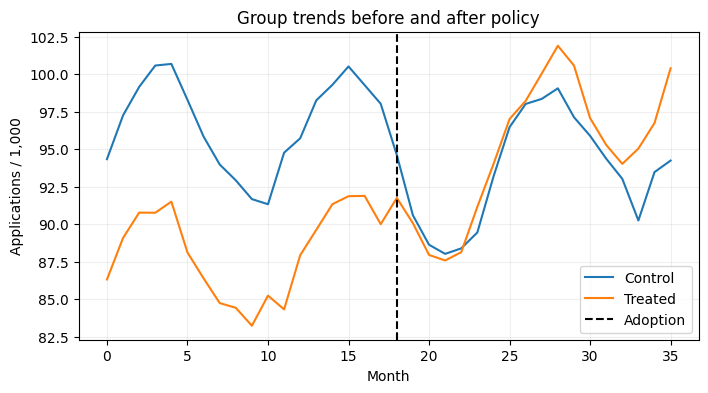

In [2]:
# Simulate time-varying macro shocks, city effects and a common policy date.
import statsmodels.formula.api as smf
from scipy.stats import norm
cities=45;months=36
selected=np.zeros(cities,dtype=int);selected[:22]=1;rng.shuffle(selected)
rows=[]
for city in range(cities):
 city_level=rng.normal(95,15);city_trend=rng.normal(.08,.10)
 for month in range(months):
    season=5*np.sin(2*np.pi*month/12);macro=2*np.sin(month/5)
    untreated=city_level+city_trend*month+season+macro+rng.normal(0,4)
    post=int(month>=18);active=int(selected[city] and post)
    # Effect grows after program adoption; truth is available to evaluate assumptions.
    tau=6+0.4*(month-18) if active else 0
    y=untreated+tau
    rows.append((city,month,int(selected[city]),active,untreated,tau,y))
panel=pd.DataFrame(rows,columns=['city','month','ever_treated','treatment','Y0','true_effect','applications_per_1000'])
print(panel.head().to_string(index=False));print('True ATT among treated post periods:',panel.loc[panel.treatment==1,'true_effect'].mean())
means=panel.groupby(['month','ever_treated']).applications_per_1000.mean().unstack()
means.rename(columns={0:'Control',1:'Treated'}).plot(title='Group trends before and after policy',xlabel='Month',ylabel='Applications / 1,000');plt.axvline(18,color='k',linestyle='--',label='Adoption');plt.legend();plt.show()

## 2. Two-period DiD from first principles

Aggregate months 12–17 as pre and 18–23 as post. The counterfactual is the control-group change, not the treatment group’s full before-after change.

In [3]:
# The hand-computed two-period contrast is an explicit teaching baseline.
sub=panel[panel.month.between(12,23)].copy();sub['post']=(sub.month>=18).astype(int)
means2=sub.groupby(['ever_treated','post']).applications_per_1000.mean()
manual=(means2[1,1]-means2[1,0])-(means2[0,1]-means2[0,0])
truth=sub.loc[sub.treatment==1,'true_effect'].mean()
print('Two-period manual DiD:',round(manual,3),'True same-window ATT:',round(truth,3))

Two-period manual DiD: 7.563 True same-window ATT: 7.0


## 3. Two-way fixed effects with clustered standard errors

A common adoption date makes TWFE interpretable in this controlled simulation. Standard errors are clustered at the **city** treatment-assignment level, rather than treating 36 observations per city as independent.

In [4]:
# TWFE with cluster-robust errors; target is simulated program ATT.
fit=smf.ols('applications_per_1000 ~ treatment + C(city) + C(month)',data=panel).fit(cov_type='cluster',cov_kwds={'groups':panel.city})
beta=fit.params['treatment'];se=fit.bse['treatment'];ci=(beta-1.96*se,beta+1.96*se)
truth_full=panel.loc[panel.treatment==1,'true_effect'].mean()
print('TWFE effect',round(beta,3),'cluster SE',round(se,3),'95% CI',tuple(np.round(ci,3)),'true ATT',round(truth_full,3))

TWFE effect 9.894 cluster SE 0.698 95% CI (np.float64(8.527), np.float64(11.262)) true ATT 9.4


## 4. Event-study design and parallel-trend diagnostics

Event-time interactions show effects before and after treatment. Period −1 is the omitted reference period. The pre-period coefficients should be near zero **in expectation**, but non-significance alone does not prove parallel trends.

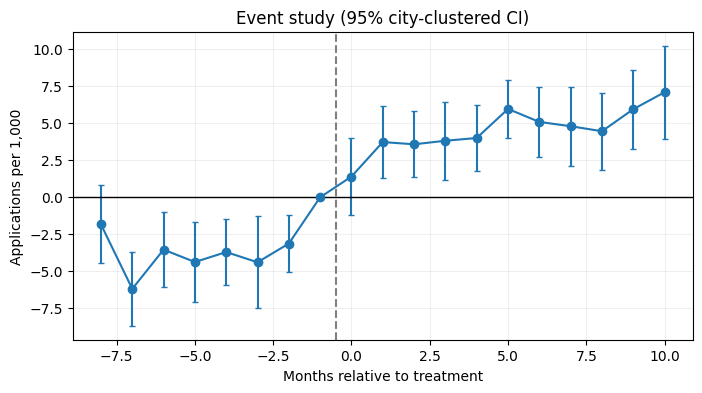

In [5]:
# Event study documents pre-trends and post-adoption dynamics.
panel['event_time']=panel.month-18
for k in range(-8,11):
 if k==-1:continue
 panel[f'evt_{"n"+str(-k) if k<0 else "p"+str(k)}']=((panel.ever_treated==1)&(panel.event_time==k)).astype(int)
terms=[f'evt_{"n"+str(-k) if k<0 else "p"+str(k)}' for k in range(-8,11) if k!=-1]
event_fit=smf.ols('applications_per_1000 ~ '+' + '.join(terms)+' + C(city) + C(month)',data=panel).fit(cov_type='cluster',cov_kwds={'groups':panel.city})
values=[]
for k in range(-8,11):
 if k==-1:values.append((k,0,0));continue
 col=f'evt_{"n"+str(-k) if k<0 else "p"+str(k)}';values.append((k,event_fit.params[col],event_fit.bse[col]))
es=pd.DataFrame(values,columns=['event_month','effect','se'])
plt.errorbar(es.event_month,es.effect,yerr=1.96*es.se,fmt='o-',capsize=2);plt.axhline(0,color='k',linewidth=1);plt.axvline(-.5,color='gray',linestyle='--');plt.xlabel('Months relative to treatment');plt.ylabel('Applications per 1,000');plt.title('Event study (95% city-clustered CI)');plt.show()

## 5. Placebo and violated parallel-trend experiment

A fake treatment assigned entirely in the pre-period should not show a systematic impact under the clean DGP. Then we **deliberately violate** parallel trends to demonstrate how DiD can fail.

In [6]:
# Intentional violation demonstrates failure of parallel trends.
pre=panel[panel.month<18].copy();pre['placebo']=(pre.ever_treated.eq(1)&pre.month.ge(10)).astype(int)
placebo=smf.ols('applications_per_1000 ~ placebo + C(city) + C(month)',data=pre).fit(cov_type='cluster',cov_kwds={'groups':pre.city})
print('Pre-period placebo:',round(placebo.params['placebo'],3),'SE',round(placebo.bse['placebo'],3))
violated=panel.copy();violated['bad_outcome']=violated.applications_per_1000+violated.ever_treated*violated.month*.40
bad_fit=smf.ols('bad_outcome ~ treatment + C(city) + C(month)',data=violated).fit(cov_type='cluster',cov_kwds={'groups':violated.city})
print('Estimate after unmodeled differential group trend:',round(bad_fit.params['treatment'],2),'vs true',round(truth_full,2))

Pre-period placebo: 0.814 SE 0.697
Estimate after unmodeled differential group trend: 17.09 vs true 9.4


## What the results mean / interview discussion

DiD depends on the evolution of **untreated potential outcomes**, not simply visual similarity of observed pretrends. Common policy onset avoids staggered-adoption negative-weight pitfalls; an extension should use group-time ATT methods (e.g., Callaway–Sant’Anna) if cohorts adopt in different months.

**Try explaining these without looking at the code:**

1. What does parallel trends mean formally?
2. Why do city-clustered standard errors matter?
3. What changes for staggered policy adoption with heterogeneous effects?

**Limitations and next step:** Evaluate on a suitably licensed real-world dataset or stronger simulation with domain shift, logging bias and realistic selection. Never treat synthetic performance as production evidence.

## What this project demonstrates, and what it does not

**Next:** run group-time ATT with genuinely staggered rollout, check anticipation and spillovers, and weight rates thoughtfully. Pretrend tests cannot prove parallel trends; the deliberate trend violation illustrates that limitation.

**Reproduce:** `Run All` in Jupyter; no private or uploaded data required. For real data, use leakage-safe train/validation/test partitions and respect each dataset license.